# Avaliação da busca: o quanto o índice acha a resposta certa

Este notebook lê os resultados do `scripts/avaliar.py` e mostra, com gráficos, **quão bem a busca
densa encontra a resposta certa** nos 20.665 chunks, e **se dá para o sistema recusar oferecer uma resposta**
quando a pergunta não tem resposta nos livros. Cada métrica é explicada na hora em que aparece.

**De onde vêm os dados**
- `data/golden/pares.csv`: 205 perguntas sorteadas (5 por livro). Cada uma vem em três tipos de
  consulta, todos com **a mesma resposta certa** (o mesmo `id_original`):
  - **original**: a pergunta do livro, como está;
  - **reescrita** (3 versões): o mesmo sentido, com outras palavras;
  - **vaga** (3 versões): o que alguém que não sabe bem o que procurar digitaria.

  Nas três versões, a 1 é a revisada pela Isabela (ou no estilo dela), a 2 usa o termo do livro e
  a 3 só descreve o que a pessoa vê ou quer, sem o termo.
- `data/golden/fora_do_escopo.csv`: 100 consultas que os livros **não** respondem, 50 de outro
  assunto (culinária, futebol...) e 50 de agricultura fora dos 41 livros (café, cacau, cana...).
- `results/e5-small-fp32/`: o que o `avaliar.py` calculou para cada consulta (posição da resposta
  certa, scores do 1º e do 2º colocados etc.).

**Como rodar:** primeiro `python scripts/avaliar.py` (precisa do modelo), depois este notebook, que
só lê arquivos e precisa de `pandas` e `matplotlib`. Depois de mudar o golden set (revisão), rode
o `avaliar.py` de novo e reexecute o notebook: todos os números e gráficos se atualizam.

**Roteiro** (o resumo dos achados vem logo abaixo)
0. Preparação
1. Os dados da avaliação
2. Como a busca é medida: posição, Recall@k e MRR@k
3. Qualidade do ranking por conjunto
4. Robustez: o pior caso entre as versões
5. Onde a resposta certa aparece
6. Análise pareada: a mesma pergunta em três versões
7. Os erros: quem ficou no lugar da resposta certa
8. Desempenho por livro
9. Os scores: score do 1º colocado e diferença para o 2º
10. Anisotropia: por que todos os scores são altos
11. Dentro × fora do escopo: AUROC e curva ROC
12. Limiares de abstenção: o que se perde de cada lado
13. O score diz se a resposta está certa?
14. Resumo dos achados

## Resumo dos achados

Os principais resultados, antes dos detalhes. Os números são da rodada de 15/11/2026, sobre o índice
inteiro (20.665 chunks), com todas as consultas ainda em rascunho: cada pergunta tem a original, três
reescritas e três vagas. A seção 14 recalcula os números a partir dos arquivos atuais.

- **O código e o índice estão certos.** Com a pergunta original do livro, a resposta certa vem em 1º
  em 91% das vezes e entra no top 10 em 99% (MRR@10 de 0,95). A maioria dos erros é uma pergunta igual
  ou quase igual em outro livro, por exemplo "O que é produção integrada?", que aparece em trigo e em
  banana (seções 3 e 7).
- **Com outras palavras, a busca cai; com a consulta vaga, cai muito.** Na média das três versões, a
  reescrita põe a resposta em 1º em 55% das vezes e no top 10 em 79% (MRR@10 de 0,62). A vaga, em 29%
  e 54% (MRR@10 de 0,38) (seção 3).
- **A busca depende muito de repetir as palavras do livro.** A versão que usa o termo do livro acha a
  resposta no top 10 em 98% das reescritas e 95% das vagas. A versão que só descreve, sem o termo,
  acha em 53% e 32% (seção 4).
- **Robustez: o pior caso (*worst-case*).** Pegando, em cada pergunta, a versão em que a busca foi pior,
  o top 10 cai para 45% nas reescritas e 16% nas vagas. Nas vagas, metade das perguntas (104 de 205)
  só é achada em uma das três versões (seção 4).
- **Análise pareada.** Das 205 perguntas, 46% têm a resposta certa no top 10 nos três tipos (na
  maioria das versões), 43% na original e na reescrita, mas não na vaga, e 9% só na original (seção 6).
- **O erro costuma ser vizinho.** O 1º colocado é do livro certo em 80% das reescritas e 64% das
  vagas; entre os erros, cerca de metade continua no livro certo. Isso favorece reordenar perto do topo
  (reranker, busca híbrida) (seções 3 e 7).
- **Parte das respostas fica longe.** Nas vagas, 21% das respostas certas ficam abaixo da 200ª
  posição, o que um reranker sobre o top 10 não resolve sozinho (seção 5).
- **Os livros variam bastante**, mas com 5 perguntas por livro isso é só uma pista. Integração
  lavoura-pecuária-floresta, abacaxi e maçã ficaram entre os piores (seção 8).
- **A anisotropia é forte.** Dois chunks sorteados têm cosseno médio de 0,81, e o vetor médio do corpus
  tem norma 0,90. As medianas do score do 1º colocado de todos os conjuntos ficam entre 0,84 e 0,92
  (seções 9 e 10).
- **Não há um bom limiar para detectar consultas fora do escopo com o score cru.** O score do 1º separa bem as perguntas de outro
  assunto (AUROC 0,97), mas não tão bem as de agricultura fora dos livros (0,83). A diferença entre o
  1º e o 2º ajuda pouco (0,63). Para aceitar no máximo 10% das consultas fora do escopo, o sistema
  recusaria 31% das válidas. Nesse ponto de operação, a matriz de confusão dá precision de 0,99,
  recall de 0,69 e accuracy de 0,71 (seções 11 e 12).
- **O score prevê razoavelmente se a resposta está certa** (AUROC 0,80), mas ainda há muitas
  respostas erradas com score alto (seção 13).
- **Fora do escopo que chegam mais perto:** broca-da-cana, cacau, vermifugação de equinos e ração de
  frango. São temas vizinhos de livros que existem (milho, caju, gado de corte, suínos) (seção 12).

**Próximos passos sugeridos:** terminar a revisão e rodar de novo com `--so-aprovadas`; decidir como
tratar perguntas repetidas entre livros; testar a centralização dos vetores, BM25 / busca híbrida e
um reranker.

## 0. Preparação

As mesmas bibliotecas e o mesmo tema de gráficos do notebook da EDA, para os dois terem a mesma
cara. Cada conjunto de consultas tem uma cor fixa, usada em todos os gráficos.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")   # esconde avisos de versão das bibliotecas, que só poluem a saída

# ---- Tema dos gráficos (igual ao da EDA) ------------------------------------
# Troque para False se quiser os gráficos com fundo claro.
TEMA_ESCURO = True

if TEMA_ESCURO:
    FUNDO, TEXTO, TEXTO_2, GRADE, EIXO = "#1a1a19", "#f0efec", "#c3c2b7", "#33332f", "#6b6a64"
    AZUL, LARANJA, VERDE_AGUA, AMARELO, ROSA, VERDE, VIOLETA, VERMELHO = (
        "#3987e5", "#d95926", "#199e70", "#c98500", "#d55181", "#008300", "#9085e9", "#e66767")
    ESCALA = "Blues_r"   # mapa de calor: escuro = pouco, claro = muito
else:
    FUNDO, TEXTO, TEXTO_2, GRADE, EIXO = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0", "#8a8984"
    AZUL, LARANJA, VERDE_AGUA, AMARELO, ROSA, VERDE, VIOLETA, VERMELHO = (
        "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
    ESCALA = "Blues"     # mapa de calor: claro = pouco, escuro = muito
CINZA = "#8a8984"

plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110,
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": EIXO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": TEXTO, "axes.labelcolor": TEXTO_2, "text.color": TEXTO,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "legend.facecolor": FUNDO, "legend.edgecolor": EIXO,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 110)

# ---- Os cinco conjuntos de consultas: ordem, nome e cor fixos ----------------
DENTRO = ["original", "reescrita", "vaga"]   # têm resposta certa (id_original)
FORA = ["fora_geral", "fora_agro"]           # não têm resposta nos livros
CONJUNTOS = DENTRO + FORA
NOMES = {"original": "Originais", "reescrita": "Reescritas", "vaga": "Vagas",
         "fora_geral": "Fora: outro assunto", "fora_agro": "Fora: agro sem livro"}
CORES = {"original": AZUL, "reescrita": LARANJA, "vaga": VERDE_AGUA,
         "fora_geral": VIOLETA, "fora_agro": ROSA}

## 1. Os dados da avaliação

O `avaliar.py` grava, para a variante do índice (aqui `e5-small-fp32`):
- `por_consulta.csv`: uma linha por consulta, com a posição da resposta certa, os scores e qual
  pergunta ficou em 1º;
- `metricas.json`: os números já agregados (médias, intervalos de confiança, AUROC);
- `por_livro.csv` e `limiares_*.csv`: os recortes por livro e por limiar.

As funções `auroc` e `curva_roc` vêm do `src/avaliacao.py`, as mesmas que o script usa.

In [2]:
# O notebook fica em codigo/notebooks/; os resultados ficam em codigo/results/
RAIZ = Path.cwd().parent
if not (RAIZ / "results").exists():   # se o Jupyter não abrir na pasta do notebook
    RAIZ = Path("/Users/hissapinto/Library/CloudStorage/OneDrive-Pessoal/_CC/IC/Embrapa/codigo")
VARIANTE = "e5-small-fp32"
RES = RAIZ / "results" / VARIANTE

sys.path.insert(0, str(RAIZ / "src"))
from avaliacao import auroc, curva_roc   # noqa: E402

pc = pd.read_csv(RES / "por_consulta.csv")
with open(RES / "metricas.json", encoding="utf-8") as f:
    m = json.load(f)
por_livro = pd.read_csv(RES / "por_livro.csv")
lim_top1 = pd.read_csv(RES / "limiares_top1.csv")
lim_gap = pd.read_csv(RES / "limiares_gap.csv")
K = m["k"]

# Ordem fixa dos conjuntos nas tabelas
pc["conjunto"] = pd.Categorical(pc["conjunto"], CONJUNTOS, ordered=True)
validas = pc[pc["conjunto"].isin(DENTRO)].copy()
fora = pc[pc["conjunto"].isin(FORA)].copy()

print(f"Índice: {m['n_chunks']:,} chunks ({m['n_perguntas']:,} perguntas)".replace(",", "."))
print(f"Consultas avaliadas: {len(pc)}  |  só aprovadas: {m['so_aprovadas']}")
pc["conjunto"].value_counts(sort=False).rename("consultas").to_frame()

Índice: 20.665 chunks (20.381 perguntas)
Consultas avaliadas: 1535  |  só aprovadas: False


,consultas
conjunto,
original,205
reescrita,615
vaga,615
fora_geral,50
fora_agro,50


Um exemplo de uma mesma pergunta em todas as versões (a original e as três reescritas e três vagas),
para ver o tipo de consulta de cada conjunto.
A coluna `posicao` é onde a resposta certa apareceu no ranking (1 = primeiro lugar).

In [3]:
exemplo = validas["id_original"].iloc[0]
validas.loc[validas["id_original"] == exemplo, ["conjunto", "versao", "consulta", "posicao", "score_top1"]]

,conjunto,versao,consulta,posicao,score_top1
0,original,0.0,"Antes do plantio, que prática pode ser utilizada para controlar a cochonilha?",1.0,0.9142
1,reescrita,1.0,O que fazer com o abacaxi para não levar cochonilha para a nova plantação?,9.0,0.8885
2,reescrita,2.0,"Qual o melhor tratamento das mudas antes de plantar, para não levar praga para a lavoura de abacaxi?",1.0,0.8931
3,reescrita,3.0,"Antes de plantar, como deixo as mudas livres daquele bichinho branco que gruda no pé?",6.0,0.8620
4,vaga,1.0,inseto branco no abacaxi,183.0,0.8952
5,vaga,2.0,cochonilha na muda de abacaxi,2.0,0.9050
6,vaga,3.0,limpar muda antes de plantar,10.0,0.8954


## 2. Como a busca é medida: posição, Recall@k e MRR@k

Para cada consulta, a busca compara o vetor da consulta com os 20.665 vetores do índice e ordena
os chunks do mais parecido (maior cosseno) para o menos parecido. A pergunta é: **em que posição
ficou a resposta certa?**

**Ranking por pergunta, não por chunk.** Algumas respostas longas foram divididas em até 6 partes
(chunks), todas com o mesmo `id_original`. Para não contar a mesma pergunta várias vezes, o
ranking é **deduplicado**: cada pergunta aparece uma vez só, na posição da sua melhor parte. Achar
qualquer parte da pergunta certa conta como acerto.

**Corpus inteiro, não pool fechado.** No projeto de estudo (mMARCO), cada consulta competia com
200 documentos e o MRR deu 0,97. Aqui ela compete com todas as 20.381 perguntas, o que é bem mais
difícil e mais parecido com o uso real.

Com a posição de cada consulta, saem as métricas:

| Métrica | Pergunta que responde | Como calcula |
| --- | --- | --- |
| **Recall@k** | A resposta certa apareceu entre as k primeiras? | 1 se posição ≤ k, senão 0; média entre as consultas |
| **MRR@k** | Quão perto do topo ela ficou? | 1/posição se posição ≤ k, senão 0; média entre as consultas |
| **Livro certo no 1º** | O 1º colocado é pelo menos do livro certo? | 1 se o 1º colocado é da mesma cultura; média |

Um exemplo com 4 consultas e posições 1, 3, 2 e 40:
- Recall@1 = (1 + 0 + 0 + 0) / 4 = 0,25; Recall@10 = (1 + 1 + 1 + 0) / 4 = 0,75;
- MRR@10 = (1 + 1/3 + 1/2 + 0) / 4 = 0,458.

O MRR cai rápido: ficar em 2º já vale metade. Por isso ele é a métrica principal quando o produtor
vai ler só o primeiro resultado, e o Recall@10 importa quando os 10 primeiros vão para um gerador
(RAG).

**Três versões por pergunta.** Cada reescrita e cada vaga tem três versões. A média é feita em duas
etapas: primeiro a média das três versões de cada pergunta, depois a média entre as 205 perguntas.
Assim cada pergunta pesa igual, mesmo que uma versão seja rejeitada na revisão.

**Intervalo de confiança (IC 95%).** Com 205 perguntas, a média muda um pouco de amostra para
amostra. O *bootstrap* sorteia, com reposição, 205 perguntas entre as 205 (cada uma com a média das
suas versões), mil vezes, e olha entre que valores a média fica em 95% das vezes. Sorteia-se a
pergunta, e não a consulta, porque as três versões de uma pergunta não são independentes. Se os intervalos de duas variantes se
sobrepõem muito, a diferença entre elas pode ser só acaso.

A célula abaixo refaz a conta a partir do `por_consulta.csv` (média por pergunta, depois entre
perguntas) e deve bater com o `metricas.json`.

In [4]:
# Recalcula MRR@10 e Recall@k direto da coluna "posicao", só para ver a conta acontecendo:
# 1) métrica de cada consulta; 2) média das versões de cada pergunta; 3) média entre as perguntas.
v = validas.assign(**{f"MRR@{K}": np.where(validas["posicao"] <= K, 1 / validas["posicao"], 0),
                      "Recall@1": validas["posicao"] <= 1,
                      "Recall@5": validas["posicao"] <= 5,
                      f"Recall@{K}": validas["posicao"] <= K})
colunas = [f"MRR@{K}", "Recall@1", "Recall@5", f"Recall@{K}"]
conta = (v.groupby(["conjunto", "id_original"], observed=True)[colunas].mean()   # média por pergunta
          .groupby("conjunto", observed=True).mean())                             # média entre perguntas
conta["posição mediana"] = validas.groupby("conjunto", observed=True)["posicao"].median()
conta.round(3)

,MRR@10,Recall@1,Recall@5,Recall@10,posição mediana
conjunto,,,,,
original,0.947,0.912,0.985,0.990,1.0
reescrita,0.620,0.550,0.711,0.785,1.0
vaga,0.375,0.291,0.491,0.538,6.0


## 3. Qualidade do ranking por conjunto

As barras são as médias e os traços pretos, o intervalo de confiança de 95%.

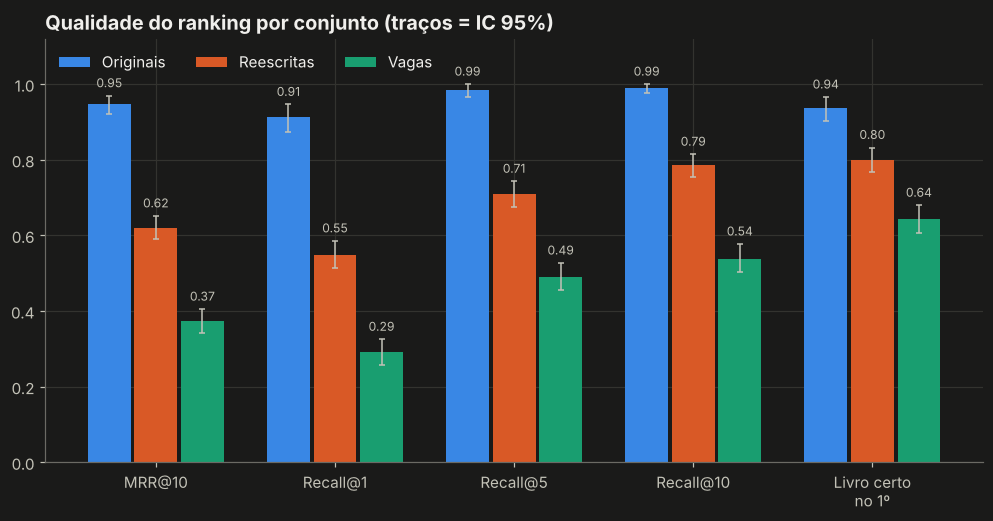

,mrr@10,recall@1,recall@5,recall@10,livro_certo@1,perguntas,consultas
Originais,0.947 (0.92–0.97),0.912 (0.87–0.95),0.985 (0.97–1.00),0.990 (0.98–1.00),0.937 (0.90–0.97),205,205
Reescritas,0.620 (0.59–0.65),0.550 (0.51–0.59),0.711 (0.68–0.74),0.785 (0.75–0.81),0.798 (0.77–0.83),205,615
Vagas,0.375 (0.34–0.40),0.291 (0.26–0.33),0.491 (0.46–0.53),0.538 (0.50–0.58),0.642 (0.61–0.68),205,615
reescrita+vaga,0.497 (0.47–0.52),0.420 (0.39–0.45),0.601 (0.57–0.63),0.662 (0.63–0.69),0.720 (0.69–0.75),205,1230


In [5]:
nomes_m = [f"mrr@{K}", "recall@1", "recall@5", f"recall@{K}", "livro_certo@1"]
rotulos = [f"MRR@{K}", "Recall@1", "Recall@5", f"Recall@{K}", "Livro certo\nno 1º"]
fig, ax = plt.subplots(figsize=(11, 5))
largura = 0.26
x0 = np.arange(len(nomes_m))
for j, c in enumerate(DENTRO):
    r = m["ranking"][c]
    v = np.array([r[n]["valor"] for n in nomes_m])
    lo = v - np.array([r[n]["ic95"][0] for n in nomes_m])
    hi = np.array([r[n]["ic95"][1] for n in nomes_m]) - v
    xs = x0 + (j - 1) * largura
    ax.bar(xs, v, width=largura * 0.92, color=CORES[c], label=NOMES[c])
    ax.errorbar(xs, v, yerr=[lo, hi], fmt="none", ecolor=TEXTO_2, elinewidth=1, capsize=2)
    for xi, vi, h in zip(xs, v, hi):
        ax.text(xi, vi + h + 0.015, f"{vi:.2f}", ha="center", va="bottom", fontsize=8, color=TEXTO_2)
ax.set_xticks(x0, rotulos)
ax.set_ylim(0, 1.12)
ax.set_title("Qualidade do ranking por conjunto (traços = IC 95%)")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.show()

tabela = pd.DataFrame({NOMES.get(c, c): {n: f"{r[n]['valor']:.3f} ({r[n]['ic95'][0]:.2f}–{r[n]['ic95'][1]:.2f})"
                                         for n in nomes_m} | {"perguntas": r["n"], "consultas": r.get("n_consultas", r["n"])}
                       for c, r in m["ranking"].items()}).T
tabela

**Como ler.** As originais são o **teto**: a pergunta está dentro do texto do chunk, então a busca
quase sempre acerta. Servem para conferir que o código e o índice estão certos, não para medir o
uso real. As reescritas e as vagas são o que importa. A queda da original para a reescrita mostra o
quanto a busca depende de repetir as palavras do livro.

Repare na última coluna: mesmo quando a pergunta certa não vem em 1º, o 1º colocado costuma ser do
**livro certo**. O erro é quase sempre "vizinho", dentro do mesmo tema.

## 4. Robustez: o pior caso entre as versões

A média esconde uma coisa: a busca pode ir bem em duas versões de uma pergunta e mal na terceira. Um
produtor que escreve do jeito "errado" para a busca fica sem resposta. Para medir isso, para cada
pergunta pega-se a **versão em que a busca foi pior** (a de maior posição) e faz-se a média entre as
perguntas. Isso se chama **pior caso** (*worst-case*). Se o pior caso fica muito abaixo da média, a busca depende bastante de como a pergunta
é escrita.

As barras claras são a média das três versões (a mesma da seção 3); as escuras, o pior caso.

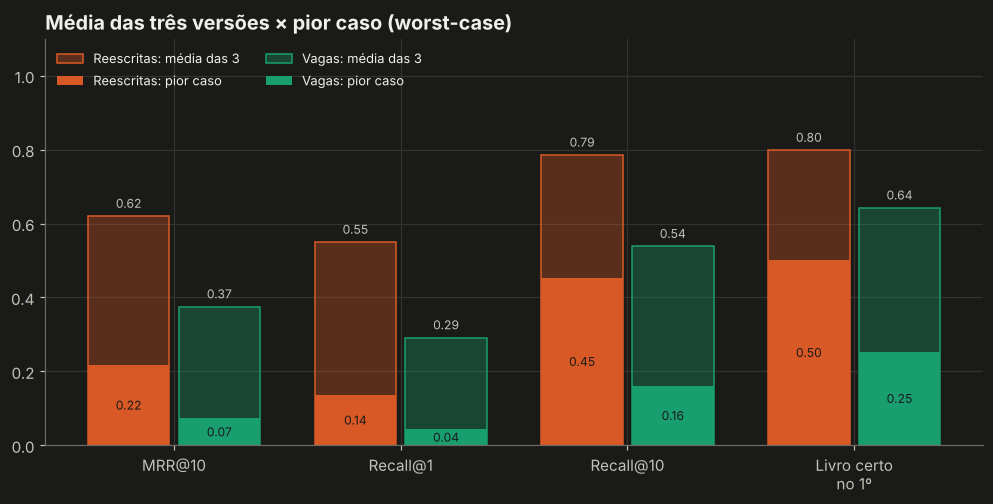

,Reescritas (média),Reescritas (pior caso),Vagas (média),Vagas (pior caso)
mrr@10,0.620,0.217,0.375,0.073
recall@1,0.550,0.137,0.291,0.044
recall@10,0.785,0.454,0.538,0.161
livro_certo@1,0.798,0.502,0.642,0.254


In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8))
nomes_r = [f"mrr@{K}", "recall@1", f"recall@{K}", "livro_certo@1"]
rot_r = [f"MRR@{K}", "Recall@1", f"Recall@{K}", "Livro certo\nno 1º"]
x0 = np.arange(len(nomes_r))
for j, c in enumerate(["reescrita", "vaga"]):
    media = np.array([m["ranking"][c][n]["valor"] for n in nomes_r])
    pior = np.array([m["robustez"][c][n]["valor"] for n in nomes_r])
    xs = x0 + (j - 0.5) * 0.4
    ax.bar(xs, media, width=0.36, color=CORES[c] + "55", edgecolor=CORES[c], label=f"{NOMES[c]}: média das 3")
    ax.bar(xs, pior, width=0.36, color=CORES[c], label=f"{NOMES[c]}: pior caso")
    for xi, a, b in zip(xs, media, pior):
        ax.text(xi, a + 0.015, f"{a:.2f}", ha="center", va="bottom", fontsize=8, color=TEXTO_2)
        ax.text(xi, b / 2, f"{b:.2f}", ha="center", va="center", fontsize=8, color=FUNDO)
ax.set_xticks(x0, rot_r)
ax.set_ylim(0, 1.1)
ax.set_title("Média das três versões × pior caso (worst-case)")
ax.legend(frameon=False, ncol=2, fontsize=8.5, loc="upper left")
plt.show()

pd.DataFrame({f"{NOMES[c]} ({tipo})": {n: m[chave][c][n]["valor"] for n in nomes_r}
              for c in ["reescrita", "vaga"] for tipo, chave in [("média", "ranking"), ("pior caso", "robustez")]}).round(3)

Quantas das três versões de cada pergunta põem a resposta no top 10? Se a maior parte das perguntas
ficasse em "3 de 3" ou "0 de 3", as versões estariam todas no mesmo nível de dificuldade. Muitas
perguntas em "1 de 3" ou "2 de 3" mostram que a forma de escrever pesa.

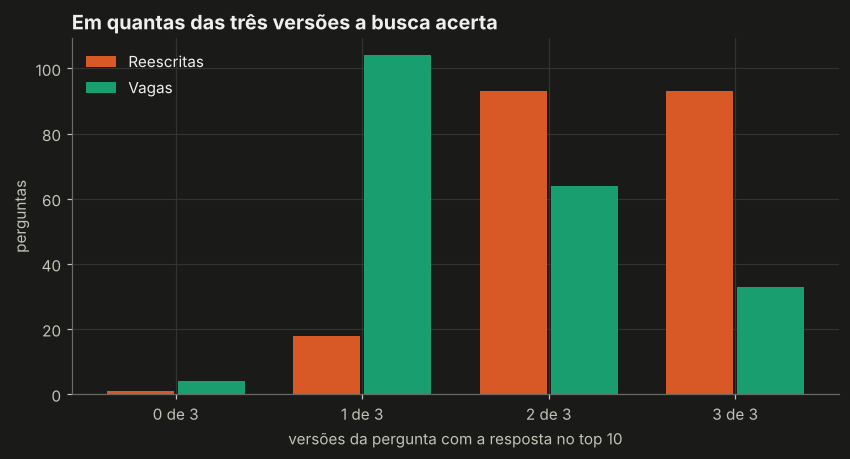

,Reescritas,Vagas
0 de 3,1,4
1 de 3,18,104
2 de 3,93,64
3 de 3,93,33


In [7]:
acertos = (validas[validas["conjunto"].isin(["reescrita", "vaga"])]
           .assign(acerto=lambda d: d["posicao"] <= K)
           .groupby(["conjunto", "id_original"], observed=True)["acerto"].sum()
           .unstack("conjunto"))
dist_versoes = pd.DataFrame({NOMES[c]: acertos[c].value_counts().reindex([0, 1, 2, 3], fill_value=0)
                             for c in ["reescrita", "vaga"]})
dist_versoes.index = [f"{i} de 3" for i in dist_versoes.index]

fig, ax = plt.subplots(figsize=(9, 4.2))
x0 = np.arange(len(dist_versoes))
for j, c in enumerate(["reescrita", "vaga"]):
    ax.bar(x0 + (j - 0.5) * 0.38, dist_versoes[NOMES[c]], width=0.36, color=CORES[c], label=NOMES[c])
ax.set_xticks(x0, dist_versoes.index)
ax.set_xlabel(f"versões da pergunta com a resposta no top {K}")
ax.set_ylabel("perguntas")
ax.set_title("Em quantas das três versões a busca acerta")
ax.legend(frameon=False)
plt.show()
dist_versoes

Cada versão separada. Na prática, as versões ficaram em três níveis de distância do texto do livro:
a **versão 1** é a que a Isabela revisou ou que foi escrita no estilo dela; a **versão 2** é a que
usa o termo do livro (repete cerca de 70% das palavras da original); a **versão 3** só descreve o
que a pessoa vê ou quer, sem o termo (repete menos de 10%). A diferença entre elas mostra o quanto
a busca depende de repetir as palavras do livro.

In [8]:
pd.DataFrame(m["por_versao"]).T.round(3)

,n,mrr@10,recall@1,recall@5,recall@10,livro_certo@1
reescrita_1,205.0,0.637,0.537,0.771,0.849,0.863
reescrita_2,205.0,0.907,0.873,0.956,0.976,0.971
reescrita_3,205.0,0.315,0.239,0.405,0.532,0.561
vaga_1,205.0,0.191,0.112,0.302,0.341,0.698
vaga_2,205.0,0.755,0.634,0.912,0.951,0.878
vaga_3,205.0,0.180,0.127,0.259,0.322,0.351


## 5. Onde a resposta certa aparece

O Recall@10 diz só se a resposta entrou no top 10. Aqui está a distribuição completa da posição,
em faixas. Se as respostas que faltam ficam logo abaixo do 10º lugar, um **reranker** (um segundo
modelo que reordena os primeiros resultados) pode trazê-las para cima. Se ficam muito longe, o
problema está no vetor e não na ordem.

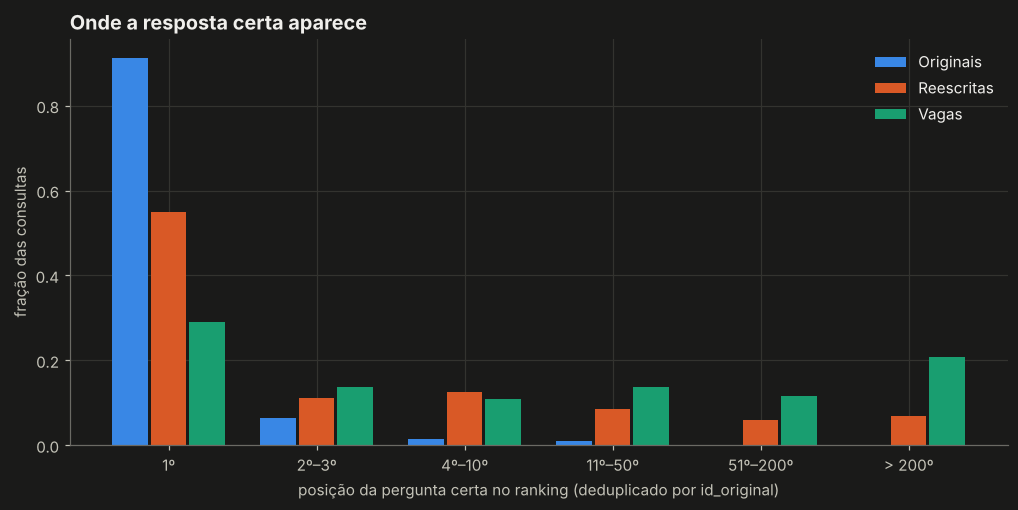

,Originais,Reescritas,Vagas
1º,91.2%,55.0%,29.1%
2º–3º,6.3%,11.1%,13.8%
4º–10º,1.5%,12.5%,10.9%
11º–50º,1.0%,8.6%,13.8%
51º–200º,0.0%,5.9%,11.5%
> 200º,0.0%,7.0%,20.8%


In [9]:
faixas = [(1, 1, "1º"), (2, 3, "2º–3º"), (4, 10, "4º–10º"), (11, 50, "11º–50º"),
          (51, 200, "51º–200º"), (201, 10**9, "> 200º")]
fig, ax = plt.subplots(figsize=(11, 4.8))
x0 = np.arange(len(faixas))
dist = {}
for j, c in enumerate(DENTRO):
    pos = validas.loc[validas["conjunto"] == c, "posicao"]
    frac = [((pos >= a) & (pos <= b)).mean() for a, b, _ in faixas]
    dist[NOMES[c]] = frac
    ax.bar(x0 + (j - 1) * 0.26, frac, width=0.24, color=CORES[c], label=NOMES[c])
ax.set_xticks(x0, [f[2] for f in faixas])
ax.set_xlabel("posição da pergunta certa no ranking (deduplicado por id_original)")
ax.set_ylabel("fração das consultas")
ax.set_title("Onde a resposta certa aparece")
ax.legend(frameon=False)
plt.show()
(pd.DataFrame(dist, index=[f[2] for f in faixas]) * 100).round(1).astype(str) + "%"

## 6. Análise pareada: a mesma pergunta nos três tipos

Como todas as versões de cada pergunta miram **a mesma resposta**, dá para comparar pergunta a
pergunta, e não só as médias. Para cada uma das 205 perguntas, o gráfico mostra em quais tipos
(original, reescrita, vaga) a resposta certa entrou no top 10. Reescrita e vaga têm três versões
cada; o tipo conta como acerto quando **a maioria** das versões (2 de 3) acerta. Isso separa dois
casos bem diferentes: perguntas que a busca não acha de jeito nenhum e perguntas que ela só acha
quando as palavras do livro aparecem.

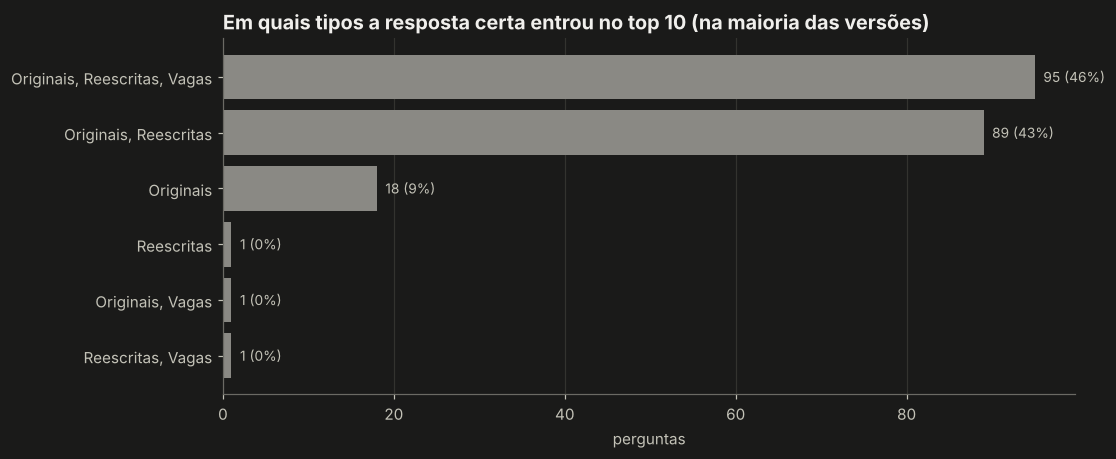

In [10]:
# Acerto de cada consulta no top-K; por pergunta e tipo, a fração de versões que acertaram.
frac = (validas.assign(acerto=validas["posicao"] <= K)
               .pivot_table(index="id_original", columns="conjunto", values="acerto", aggfunc="mean", observed=True)
               .dropna())   # só perguntas com os três tipos avaliados
acertou = frac > 0.5        # maioria das versões (a original tem uma só)
# Para o gráfico de linhas abaixo: a posição mediana das versões de cada tipo.
largo = validas.pivot_table(index="id_original", columns="conjunto", values="posicao",
                            aggfunc="median", observed=True).loc[frac.index]
combinacao = acertou.apply(lambda l: ", ".join(NOMES[c] for c in DENTRO if l[c]) or "nenhuma", axis=1)
contagem = combinacao.value_counts()

fig, ax = plt.subplots(figsize=(10, 0.5 * len(contagem) + 1.2))
ax.barh(contagem.index[::-1], contagem.values[::-1], color=CINZA)
for i, v in enumerate(contagem.values[::-1]):
    ax.text(v + 1, i, f"{v} ({v / len(frac):.0%})", va="center", fontsize=9, color=TEXTO_2)
ax.set_xlabel("perguntas")
ax.set_title(f"Em quais tipos a resposta certa entrou no top {K} (na maioria das versões)")
ax.grid(axis="y", visible=False)
plt.show()

O mesmo, posição a posição: cada linha liga a posição da original (esquerda) à da reescrita (meio)
e à da vaga (direita) de uma mesma pergunta. Para reescrita e vaga, o ponto é a **posição mediana**
das três versões. O eixo está em escala log, porque as posições vão de 1 a milhares. Linhas que
descem muito são perguntas que só são achadas com as palavras do livro.

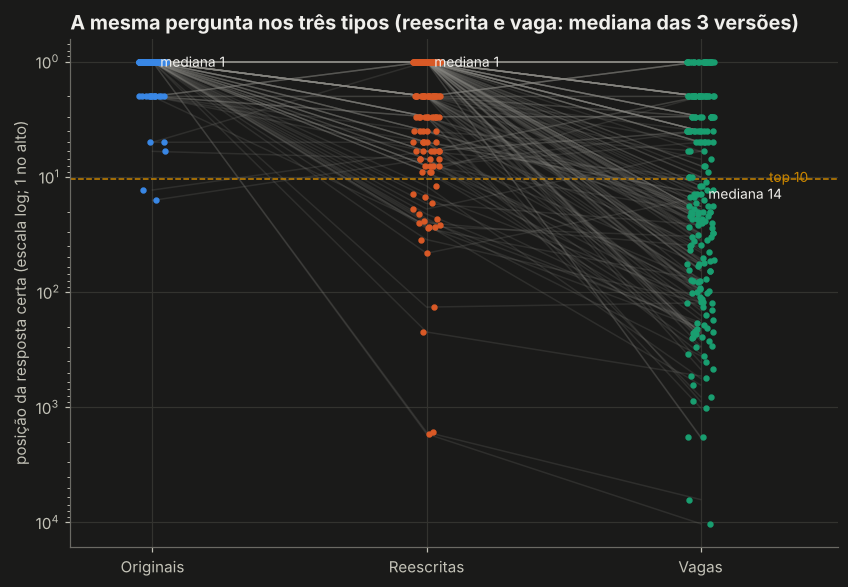

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
for _, l in largo.iterrows():
    ax.plot([0, 1, 2], [l["original"], l["reescrita"], l["vaga"]], color=CINZA, alpha=0.18, linewidth=1)
for j, c in enumerate(DENTRO):
    ax.scatter(np.full(len(largo), j) + np.random.default_rng(j).uniform(-0.05, 0.05, len(largo)),
               largo[c], s=10, color=CORES[c], zorder=3)
    ax.text(j, largo[c].median(), f"  mediana {largo[c].median():.0f}", va="center", fontsize=9, color=TEXTO)
ax.axhline(K + 0.5, color=AMARELO, linewidth=1, linestyle="--")
ax.text(2.25, K, f"top {K}", color=AMARELO, fontsize=9, va="center")
ax.set_yscale("log")
ax.invert_yaxis()   # posição 1 no alto
ax.set_xticks([0, 1, 2], [NOMES[c] for c in DENTRO])
ax.set_xlim(-0.3, 2.5)
ax.set_ylabel("posição da resposta certa (escala log; 1 no alto)")
ax.set_title("A mesma pergunta nos três tipos (reescrita e vaga: mediana das 3 versões)")
plt.show()

Algumas reescritas que ficaram fora do top 10 em perguntas que a original acha em 1º. Olhar esses
casos ajuda a ver se a reescrita mudou demais o sentido (e deve ser revisada) ou se a busca é que
falhou.

In [12]:
# Reescritas (cada versão é uma linha) que erraram o top-K numa pergunta que a original acerta em 1º
orig_1 = validas.loc[(validas["conjunto"] == "original") & (validas["posicao"] == 1), "id_original"]
originais = validas[validas["conjunto"] == "original"].set_index("id_original")["consulta"]
casos = validas[(validas["conjunto"] == "reescrita") & validas["id_original"].isin(orig_1) & (validas["posicao"] > K)]
print(f"{len(casos)} reescritas (de {(validas['conjunto'] == 'reescrita').sum()}) nessa situação; as 12 primeiras:")
pd.DataFrame({"original": casos["id_original"].map(originais).values,
              "versão": casos["versao"].astype(int).values,
              "reescrita": casos["consulta"].values,
              "posição da reescrita": casos["posicao"].astype(int).values,
              "1º colocado da reescrita": casos["top1_pergunta"].values}).head(12)

117 reescritas (de 615) nessa situação; as 12 primeiras:


,original,versão,reescrita,posição da reescrita,1º colocado da reescrita
0,Como escolher a área de plantio do abacaxizeiro?,1,O que uma lavoura precisa para se plantar abacaxi?,46,Como deve ser feito o plantio do abacaxizeiro em áreas extensas e com pequena declividade do solo (até 5%)?
1,Como escolher a área de plantio do abacaxizeiro?,3,Que tipo de terreno e de clima devo procurar antes de abrir uma roça nova?,369,Quais os cuidados recomendados no preparo do solo?
2,Quando deve ser feito o desbaste de mudas?,1,Qual a época certa para tirar os brotos que sobram no pé de abacaxi?,35,Quando deve ser feita a proteção dos frutos do abacaxizeiro contra a queima solar?
3,Quando deve ser feito o desbaste de mudas?,3,Quando é bom arrancar os filhotes a mais do abacaxizeiro?,81,Por que o desbaste de mudas pode ajudar a aumentar o peso do fruto do abacaxizeiro?
4,O que é cultura de tecidos?,1,Como multiplicar algodão em laboratório?,270,Como produzir algodão orgânico?
5,O que se entende por espaçamento e densidade de plantio numa lavoura de algodão?,1,Como saber a distância entre linhas e a quantidade de algodão por metro?,36,O que é Grau de Reflexão (Rd)?
6,O que se entende por espaçamento e densidade de plantio numa lavoura de algodão?,3,Quanto deixo de espaço entre fileiras e entre pés na roça?,27,"Em plantio tradicional de mandioca, as fileiras devem ficar a que distância uma da outra?"
7,Qual a composição centesimal da semente triturada (farinha integral)?,1,Quanto de proteína e gordura tem a farinha de amendoim?,12,Qual o valor nutricional do amendoim?
8,O que pode acarretar o consumo de amendoim contaminado por aflatoxinas?,3,Comer grão com fungo pode dar câncer no fígado?,73,O ser humano pode alimentar-se com grãos de feijão-caupi afetados pelas doenças bacterianas?
9,Qual a eficiência reprodutiva nas plantas eretas e nas rasteiras?,1,"Amendoim em pé ou rasteiro, qual dá mais vagem por flor?",28,Por que as cultivares rasteiras são mais produtivas do que as eretas?


## 7. Os erros: quem ficou no lugar da resposta certa

Quando a resposta certa não vem em 1º, quem vem? A tabela mostra os erros das **originais**. Se o
1º colocado tem uma pergunta igual ou quase igual, de outro livro, o "erro" é na verdade uma
pergunta repetida na coleção (a EDA achou 217 perguntas com o mesmo texto em mais de um lugar). Isso
pede uma decisão: aceitar como acerto qualquer pergunta idêntica, ou relatar à parte.

In [13]:
erros_orig = validas[(validas["conjunto"] == "original") & (validas["posicao"] > 1)]
erros_orig[["consulta", "id_original", "posicao", "top1_id_original", "top1_pergunta"]].sort_values("posicao")

,consulta,id_original,posicao,top1_id_original,top1_pergunta
7,Que cuidados devem ser observados após a cura das mudas?,abacaxi_2013_q058,2.0,manga_2013_q151,Quais os principais cuidados a serem observados após o plantio?
140,Quais as recomendações para o uso de cobertura morta no plantio de bananeira?,banana_2013_q112,2.0,banana_2013_q114,Quais as recomendações em relação à cobertura viva?
427,O que é Tanque Classe “A” e para que serve?,fruticultura-irrigada_2013_q023,2.0,feijao_2015_q190,O que é tanque USWB Classe A e qual é a finalidade de seu uso em cultivos irrigados de feijoeiro?
210,Quais são os danos causados pelo pulgão-da-inflorescência?,caju_2015_q280,2.0,banana_2013_q420,Quais os danos provocados pelo pulgão-da-bananeira?
938,Para que serve o creep grazing?,ovinos_2013_q162,2.0,ovinos_2013_q160,O que é creep grazing?
868,Como deve ser feito o controle químico?,manga_2013_q351,2.0,uva_2013_q350,Como é feito o controle químico do oídio?
714,Onde os fungos sobrevivem de uma safra para outra?,maca_2013_q344,2.0,pera_2016_q330,Onde os fungos sobrevivem de uma safra para outra?
707,Em que situações a propagação por sementes é utilizada?,maca_2013_q108,2.0,mamao_2013_q100,Qual o método de propagação mais utilizado?
1141,O que são insetos predadores?,producao-organica-de-hortalicas_2013_q220,2.0,fruticultura-irrigada_2013_q134,O que são insetos predadores?
1120,Quais as desvantagens do sistema de plantio direto?,producao-organica-de-hortalicas_2013_q135,2.0,citros_2013_q147,Por que se faz o plantio direto das coberturas em vez de usar o sistema convencional?


Nas reescritas e vagas, quantos erros (1º colocado errado) ainda caem no livro certo?

In [14]:
erros = validas[validas["posicao"] > 1]
(erros.groupby("conjunto", observed=True)["livro_certo_top1"]
      .agg(erros="size", mesmo_livro="sum", fracao="mean")
      .assign(fracao=lambda d: (d["fracao"] * 100).round(1).astype(str) + "%"))

,erros,mesmo_livro,fracao
conjunto,,,
original,18,5.0,27.8%
reescrita,277,153.0,55.2%
vaga,436,216.0,49.5%


## 8. Desempenho por livro

MRR@10 de cada livro em cada conjunto, do livro com melhor média para o pior. **Cuidado:** são só 5
perguntas por livro, então cada célula é uma pista, não uma conclusão. Um livro com MRR 0 nas
vagas pode ter tido só perguntas difíceis no sorteio. Livros parecidos (gado de corte × gado de
corte no Pantanal) tendem a "roubar" respostas um do outro.

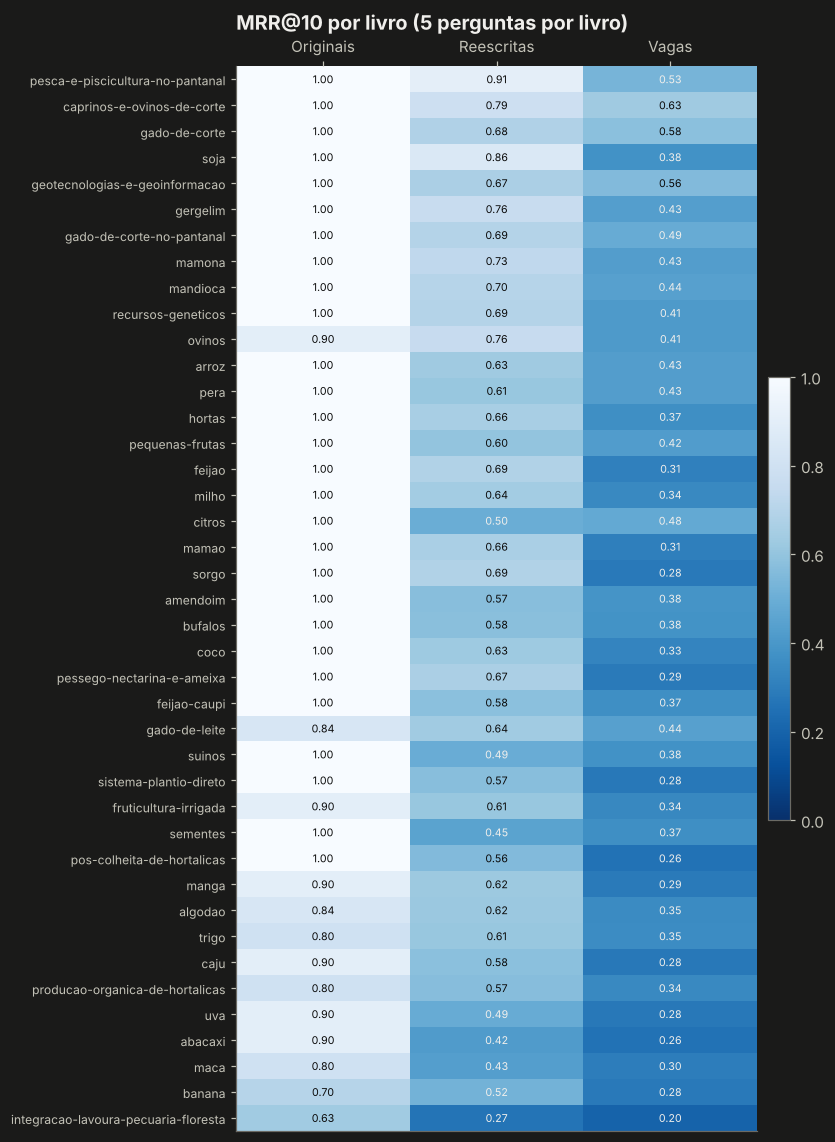

In [15]:
col = [f"mrr@{K}_{c}" for c in DENTRO]
mapa = por_livro.set_index("cultura")[col]
mapa = mapa.loc[mapa.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.5, 0.27 * len(mapa) + 1.5))
im = ax.imshow(mapa.values, aspect="auto", cmap=ESCALA, vmin=0, vmax=1)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        val = mapa.values[i, j]
        # texto escuro em célula clara e claro em célula escura (vale para os dois temas)
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7,
                color="#0b0b0b" if (val > 0.55) == TEMA_ESCURO else "#f0efec")
ax.set_xticks(range(len(DENTRO)), [NOMES[c] for c in DENTRO])
ax.set_yticks(range(len(mapa)), mapa.index, fontsize=8)
ax.xaxis.tick_top()
ax.grid(False)
ax.set_title(f"MRR@{K} por livro (5 perguntas por livro)", pad=24)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
plt.show()

## 9. Os scores: score do 1º colocado e diferença para o 2º

Até aqui olhamos a **ordem** dos resultados. Agora, o **valor** do score (o cosseno entre a
consulta e o chunk). Dois números por consulta:
- **score do 1º colocado**: o quanto o melhor resultado se parece com a consulta;
- **diferença 1º − 2º**: o quanto o 1º se destaca do 2º (entre perguntas distintas, já
  deduplicadas). Uma diferença grande sugere que a busca "tem certeza"; uma pequena, que há vários
  candidatos parecidos.

Eles interessam para a **detecção de consultas fora do escopo** (*out-of-scope detection*), em
que o sistema se abstém de responder: se as consultas fora do escopo tiverem scores
claramente menores, um limiar resolveria. Para resumir, usamos **mediana** (o valor do meio) e
**IQR** (intervalo interquartil, Q3 − Q1: a largura da faixa onde ficam os 50% do meio). Os dois não
se deixam levar por valores extremos, ao contrário da média e do desvio padrão.

Nos gráficos, a caixa vai de Q1 a Q3, o traço é a mediana e cada ponto é uma consulta.

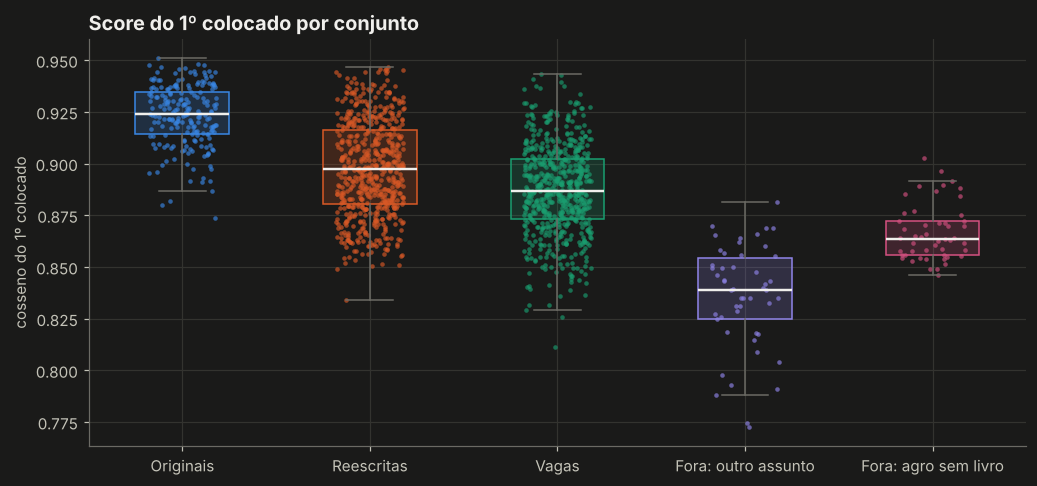

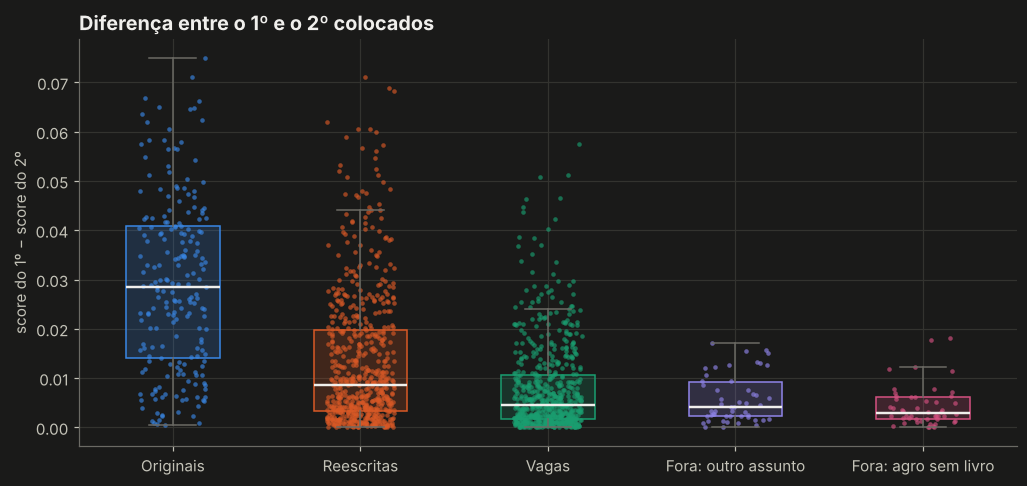

,score do 1º: mediana,score do 1º: IQR,diferença 1º−2º: mediana,diferença 1º−2º: IQR
Originais,0.924,0.020,0.029,0.027
Reescritas,0.897,0.036,0.009,0.016
Vagas,0.886,0.029,0.004,0.009
Fora: outro assunto,0.839,0.029,0.004,0.007
Fora: agro sem livro,0.864,0.016,0.003,0.005


In [16]:
def caixas(campo, titulo, rotulo):
    fig, ax = plt.subplots(figsize=(11, 4.8))
    dados = [pc.loc[pc["conjunto"] == c, campo].values for c in CONJUNTOS]
    bp = ax.boxplot(dados, widths=0.5, showfliers=False, patch_artist=True,
                    medianprops={"color": TEXTO, "linewidth": 1.6},
                    whiskerprops={"color": EIXO}, capprops={"color": EIXO})
    rng = np.random.default_rng(0)
    for i, (patch, c, v) in enumerate(zip(bp["boxes"], CONJUNTOS, dados), start=1):
        patch.set_facecolor(CORES[c] + "33")
        patch.set_edgecolor(CORES[c])
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=9, color=CORES[c], alpha=0.65, linewidths=0)
    ax.set_xticks(range(1, len(CONJUNTOS) + 1), [NOMES[c] for c in CONJUNTOS])
    ax.set_ylabel(rotulo)
    ax.set_title(titulo)
    plt.show()

caixas("score_top1", "Score do 1º colocado por conjunto", "cosseno do 1º colocado")
caixas("gap_top1_top2", "Diferença entre o 1º e o 2º colocados", "score do 1º − score do 2º")

resumo_scores = pd.DataFrame({
    NOMES[c]: {"score do 1º: mediana": s["score_top1"]["mediana"], "score do 1º: IQR": s["score_top1"]["iqr"],
               "diferença 1º−2º: mediana": s["gap_top1_top2"]["mediana"], "diferença 1º−2º: IQR": s["gap_top1_top2"]["iqr"]}
    for c, s in m["scores"].items()}).T
resumo_scores.round(3)

**Como ler.** As originais têm o score do 1º mais alto e uma diferença 1º−2º clara, porque o chunk
certo contém a própria pergunta. Nas reescritas e nas vagas, a diferença para o 2º fica perto de
zero: vários chunks parecem igualmente bons. As perguntas de outro assunto têm scores menores, mas as
de agricultura fora dos livros ficam no meio das válidas. A sobreposição fica clara no histograma
abaixo.

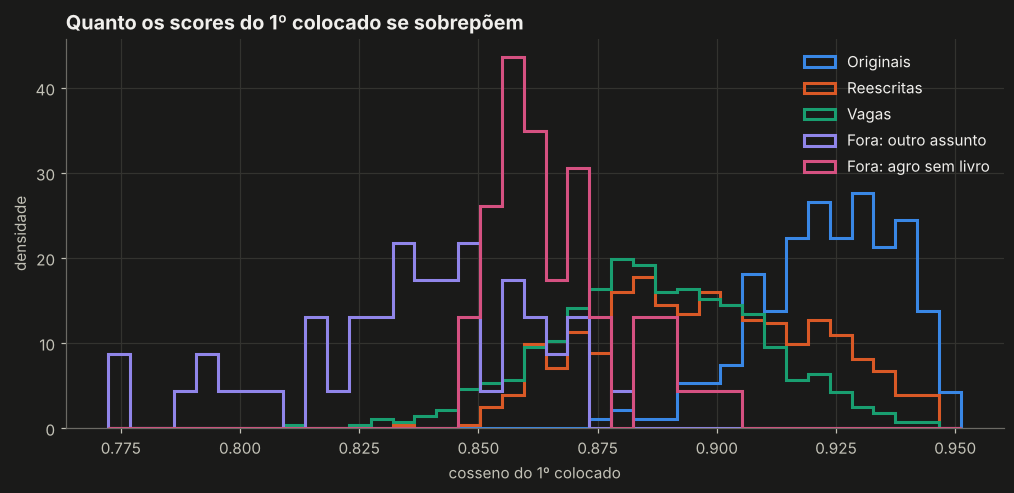

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.6))
bins = np.linspace(pc["score_top1"].min(), pc["score_top1"].max(), 40)
for c in CONJUNTOS:
    ax.hist(pc.loc[pc["conjunto"] == c, "score_top1"], bins=bins, density=True,
            histtype="step", linewidth=2, color=CORES[c], label=NOMES[c])
ax.set_xlabel("cosseno do 1º colocado")
ax.set_ylabel("densidade")
ax.set_title("Quanto os scores do 1º colocado se sobrepõem")
ax.legend(frameon=False)
plt.show()

## 10. Anisotropia: por que todos os scores são altos

Num espaço de 384 dimensões, vetores ao acaso apontariam para todos os lados, e o cosseno entre
dois textos sem relação ficaria perto de 0. O E5 coloca **todos** os vetores num "cone" estreito:
eles apontam mais ou menos para a mesma região. Isso se chama **anisotropia**, e faz até textos sem
relação terem cosseno alto. Com um corpus só de agricultura, o efeito fica mais forte.

Duas medidas:
- **cosseno médio entre chunks sorteados**: perto de 0 num espaço sem anisotropia;
- **norma do vetor médio do corpus**: a média de vetores de tamanho 1 tem norma perto de 0 se eles
  apontam para todo lado, e perto de 1 se apontam todos para o mesmo lugar.

O gráfico mostra o cosseno entre 5.000 pares de chunks sorteados (o "fundo" do índice) e, em
linhas verticais, a mediana do score do 1º colocado de cada conjunto. Todos os conjuntos, inclusive
os de fora do escopo, ficam espremidos numa faixa estreita, logo acima do fundo.

Cosseno médio entre chunks sorteados: 0.811
Norma do vetor médio do corpus:       0.901


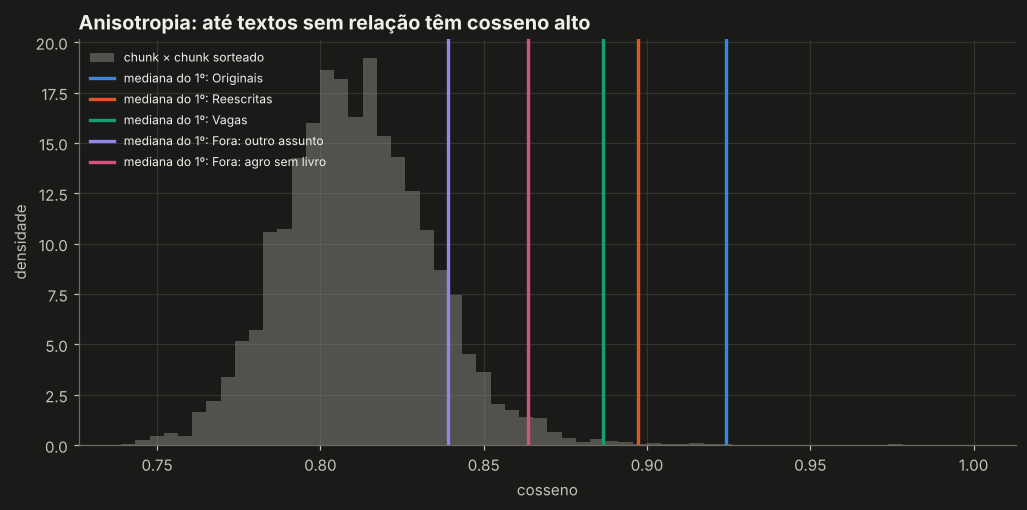

In [18]:
embs = np.load(RAIZ / "data" / "indices" / VARIANTE / "embeddings.npy")
rng = np.random.default_rng(42)   # mesma semente do avaliar.py
a, b = rng.integers(0, len(embs), 5000), rng.integers(0, len(embs), 5000)
cos_pares = np.einsum("ij,ij->i", embs[a], embs[b])

an = m["anisotropia"]
print(f"Cosseno médio entre chunks sorteados: {an['cosseno_medio_entre_chunks']:.3f}")
print(f"Norma do vetor médio do corpus:       {an['norma_do_vetor_medio']:.3f}")

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.hist(cos_pares, bins=60, range=(cos_pares.min(), 1), density=True, color=CINZA, alpha=0.5,
        label="chunk × chunk sorteado")
for c in CONJUNTOS:
    ax.axvline(pc.loc[pc["conjunto"] == c, "score_top1"].median(), color=CORES[c], linewidth=2.2,
               label=f"mediana do 1º: {NOMES[c]}")
ax.set_xlabel("cosseno")
ax.set_ylabel("densidade")
ax.set_title("Anisotropia: até textos sem relação têm cosseno alto")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

**Por que isso importa.** Para o **ranking**, quase nada: o que conta é a ordem, e o certo só
precisa ter score maior que os outros, mesmo que por pouco. Para um **limiar de abstenção**, muito:
com todos os scores entre 0,8 e 0,95, sobra pouca margem para separar o que tem resposta do que
não tem. Uma ablação possível é **centralizar os vetores** (subtrair a média do corpus antes de
normalizar), que abre o cone e espalha os scores sem treinar nada.

## 11. Dentro × fora do escopo: AUROC e curva ROC

Para detectar uma consulta fora do escopo e se abster de responder (*abstention*), o sistema precisa de um sinal que seja **alto nas consultas válidas** e
**baixo nas fora do escopo**. Os candidatos são o score do 1º colocado e a diferença 1º−2º.

**Curva ROC.** Imagine a regra "responde se o sinal ≥ t". Para cada valor de t:
- **TPR** (taxa de verdadeiros positivos) = fração das válidas que o sistema responde;
- **FPR** (taxa de falsos positivos) = fração das fora do escopo que ele responde (e não devia).

A curva liga os pontos (FPR, TPR) de todos os t possíveis. Um sinal perfeito sobe colado no eixo
vertical (responde todas as válidas antes de aceitar qualquer fora do escopo). Um sinal inútil
segue a diagonal tracejada.

**AUROC** é a área sob essa curva, e tem uma leitura simples: **a chance de uma consulta válida
sorteada ter o sinal maior que uma fora do escopo sorteada**. 1,0 = separa perfeitamente; 0,5 =
igual a cara ou coroa; abaixo de 0,5 = o sinal está invertido.

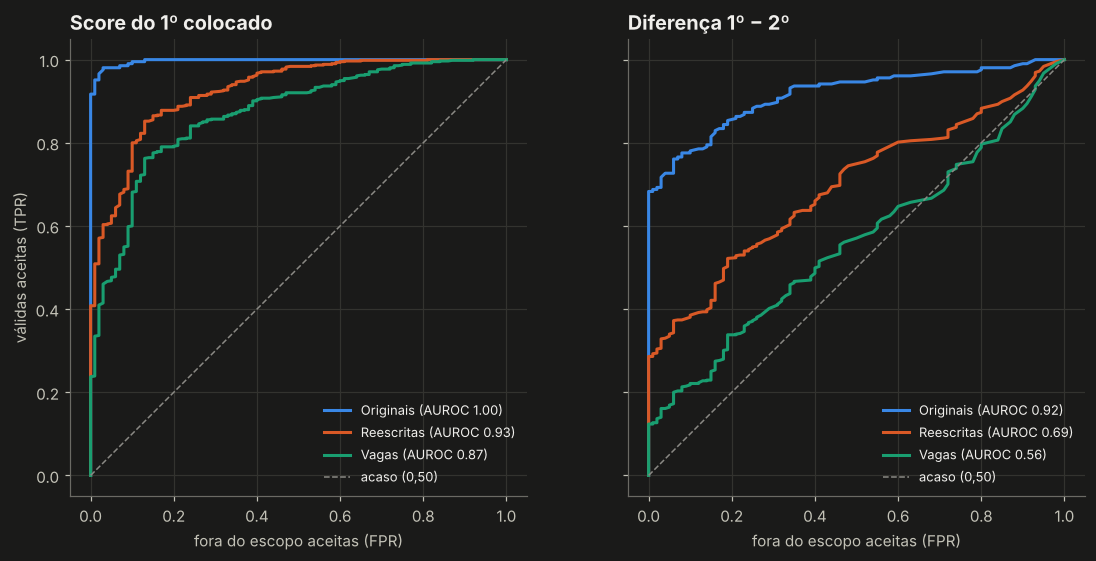

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
for ax, campo, titulo in [(axes[0], "score_top1", "Score do 1º colocado"),
                          (axes[1], "gap_top1_top2", "Diferença 1º − 2º")]:
    neg = fora[campo].values
    for c in DENTRO:
        pos = validas.loc[validas["conjunto"] == c, campo].values
        fpr, tpr, _ = curva_roc(pos, neg)
        ax.plot(fpr, tpr, color=CORES[c], linewidth=2, label=f"{NOMES[c]} (AUROC {auroc(pos, neg):.2f})")
    ax.plot([0, 1], [0, 1], color=CINZA, linewidth=1, linestyle="--", label="acaso (0,50)")
    ax.set_xlabel("fora do escopo aceitas (FPR)")
    ax.set_title(titulo)
    ax.set_aspect("equal")
    ax.legend(frameon=False, loc="lower right", fontsize=8.5)
axes[0].set_ylabel("válidas aceitas (TPR)")
plt.show()

A AUROC de cada conjunto válido contra cada tipo de consulta fora do escopo. A linha "reescrita+vaga"
junta as duas versões realistas, que é o cenário de uso.

In [20]:
tab_auroc = pd.DataFrame(m["separacao"]["auroc"]).T.rename(
    columns={"score_top1": "score do 1º", "gap_top1_top2": "diferença 1º−2º"})
tab_auroc.round(3)

,score do 1º,diferença 1º−2º
original x fora,0.997,0.916
original x fora_geral,1.000,0.901
original x fora_agro,0.994,0.930
reescrita x fora,0.926,0.694
reescrita x fora_geral,0.978,0.660
reescrita x fora_agro,0.874,0.729
vaga x fora,0.871,0.558
vaga x fora_geral,0.951,0.516
vaga x fora_agro,0.791,0.600
reescrita+vaga x fora,0.898,0.626


**Como ler.** O score do 1º separa bem as perguntas de **outro assunto** (o modelo percebe que
"capital da Austrália" não é agricultura), mas separa pior as de **agricultura fora dos livros**:
"como controlar a broca-do-café" se parece muito com as perguntas sobre outras brocas que existem
nos livros. A diferença 1º−2º, nas consultas realistas, fica em torno de 0,6: ajuda pouco como sinal.

## 12. Limiares de abstenção: o que se perde de cada lado

A curva ROC esconde o valor do limiar. Aqui ele aparece no eixo x: para cada limiar t, as linhas
cheias mostram a fração das **válidas recusadas** (erro: deixou de responder o que sabia) e as
tracejadas, a fração das **fora do escopo aceitas** (erro: respondeu o que não está nos livros).
Um bom limiar seria um ponto em que as duas estão baixas ao mesmo tempo.

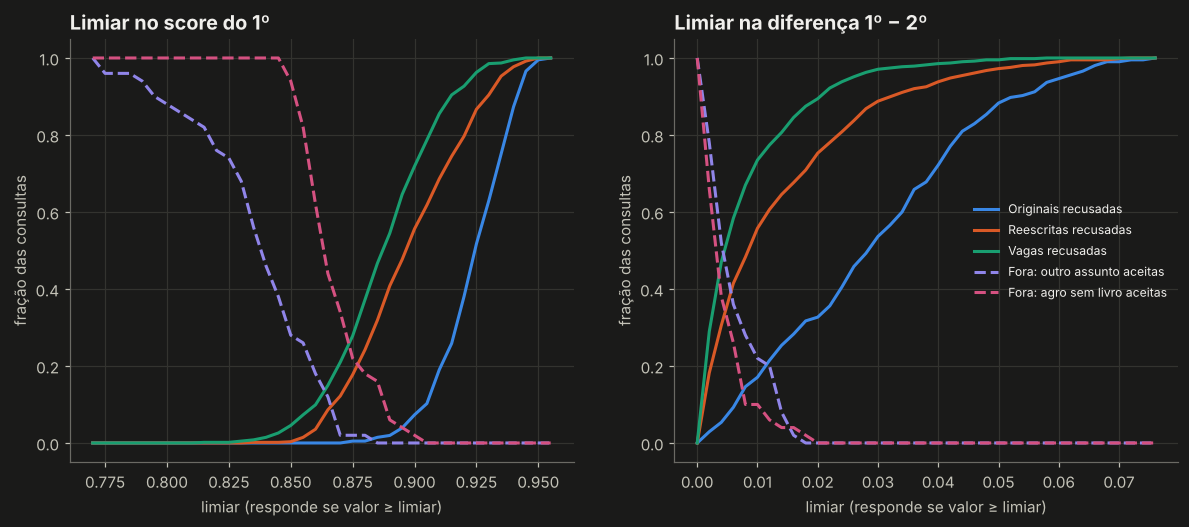

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, tabela, titulo in [(axes[0], lim_top1, "Limiar no score do 1º"),
                           (axes[1], lim_gap, "Limiar na diferença 1º − 2º")]:
    for c in DENTRO:
        ax.plot(tabela["limiar"], tabela[f"recusadas_{c}"], color=CORES[c], linewidth=2, label=f"{NOMES[c]} recusadas")
    for c in FORA:
        ax.plot(tabela["limiar"], tabela[f"aceitas_{c}"], color=CORES[c], linewidth=2, linestyle="--",
                label=f"{NOMES[c]} aceitas")
    ax.set_xlabel("limiar (responde se valor ≥ limiar)")
    ax.set_ylabel("fração das consultas")
    ax.set_title(titulo)
axes[1].legend(frameon=False, fontsize=8, loc="center right")
plt.show()

**Pontos de operação.** Os limiares de referência, para válidas = reescritas + vagas:
- "fora aceitas ≤ 5%" ou "≤ 10%": o menor limiar que aceita no máximo essa fração das fora do
  escopo, e quanto ele recusa das válidas;
- "válidas recusadas ≤ 5%" ou "≤ 10%": o maior limiar que recusa no máximo essa fração das
  válidas, e quanto ele deixa passar das fora do escopo.

In [22]:
def pontos(chave):
    tab = pd.DataFrame(m["separacao"][chave]).T.drop(columns="matriz", errors="ignore")
    return (tab.rename(columns={"recusadas_reescrita+vaga": "válidas recusadas", "aceitas_fora": "fora aceitas"})
               .style.format({"limiar": "{:.3f}", "válidas recusadas": "{:.1%}", "fora aceitas": "{:.1%}"}))
display(pontos("pontos_top1"))
display(pontos("pontos_gap"))

,limiar,válidas recusadas,fora aceitas
fora_aceitas<=5%,0.890,47.6%,3.0%
validas_recusadas<=5%,0.855,4.4%,54.0%
fora_aceitas<=10%,0.880,30.7%,10.0%
validas_recusadas<=10%,0.860,6.7%,40.0%


,limiar,válidas recusadas,fora aceitas
fora_aceitas<=5%,0.016,76.1%,3.0%
validas_recusadas<=5%,0.000,0.0%,100.0%
fora_aceitas<=10%,0.014,72.6%,6.0%
validas_recusadas<=10%,0.000,0.0%,100.0%


**Matriz de confusão, precision, recall e accuracy.** Escolhido um limiar, a detecção de fora do
escopo vira uma **classificação binária** (*binary classification*): para cada consulta, o sistema
responde (aceita) ou se abstém (recusa). Com **positivo = consulta válida**, a **matriz de confusão**
(*confusion matrix*) conta os quatro casos:

| | Sistema aceita | Sistema recusa (abstenção) |
| --- | --- | --- |
| **Consulta válida** | VP, verdadeiro positivo (*true positive*) | FN, falso negativo (*false negative*) |
| **Fora do escopo** | FP, falso positivo (*false positive*) | VN, verdadeiro negativo (*true negative*) |

- **Precision** = VP / (VP + FP): das consultas aceitas, a fração que era válida. Alta precision = quase
  nunca responde o que não está nos livros.
- **Recall** = VP / (VP + FN): das consultas válidas, a fração aceita. Alto recall = quase nunca se
  abstém quando tinha resposta. (É a mesma palavra do Recall@k, mas aqui mede outra coisa: a
  aceitação, não o ranking.)
- **Accuracy** = (VP + VN) / total: a fração de decisões certas. **Cuidado:** depende da proporção do
  teste. Aqui há 1.230 válidas e 100 fora do escopo, então aceitar tudo já daria 0,92 de accuracy.

Precision e recall puxam para lados opostos: subir o limiar aumenta a precision e derruba o recall.
A AUROC (seção 11) resume todos os limiares de uma vez; a matriz mostra o que acontece em **um**
ponto de operação (*operating point*). Abaixo, três pontos do score do 1º colocado.

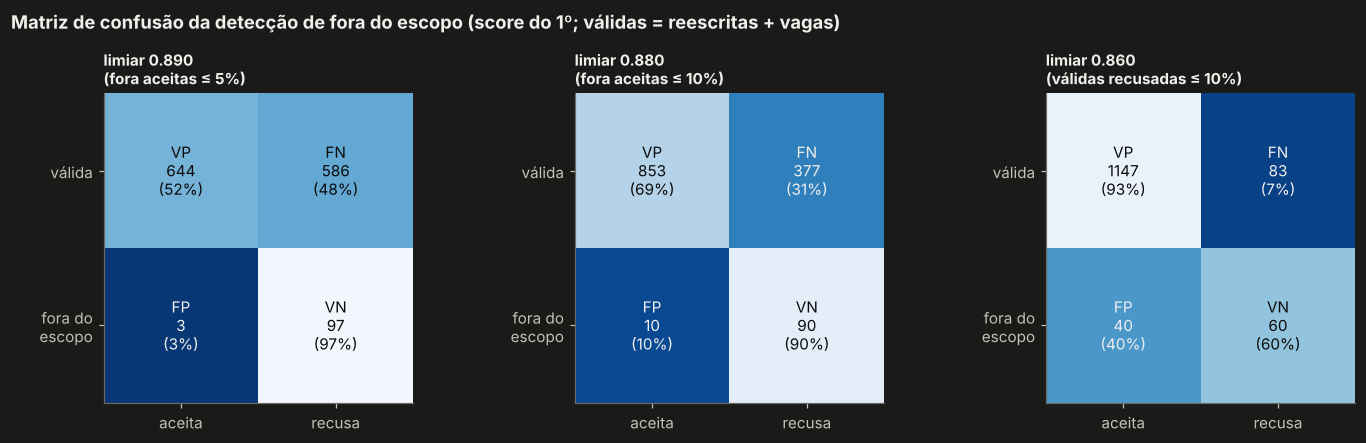

,limiar,VP,FN,FP,VN,precision,recall,accuracy
fora_aceitas<=5%,0.890,644,586,3,97,0.995,0.524,0.557
validas_recusadas<=5%,0.855,1176,54,54,46,0.956,0.956,0.919
fora_aceitas<=10%,0.880,853,377,10,90,0.988,0.693,0.709
validas_recusadas<=10%,0.860,1147,83,40,60,0.966,0.933,0.908


In [23]:
escolhidos = ["fora_aceitas<=5%", "fora_aceitas<=10%", "validas_recusadas<=10%"]
pts = m["separacao"]["pontos_top1"]
fig, axes = plt.subplots(1, len(escolhidos), figsize=(13, 4))
for ax, crit in zip(axes, escolhidos):
    mc = pts[crit]["matriz"]
    tabela_mc = np.array([[mc["vp"], mc["fn"]], [mc["fp"], mc["vn"]]])
    # cor por fração da linha: cada linha (válidas, fora) soma 100%
    frac = tabela_mc / tabela_mc.sum(axis=1, keepdims=True)
    ax.imshow(frac, cmap=ESCALA, vmin=0, vmax=1)
    rotulos_mc = [["VP", "FN"], ["FP", "VN"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{rotulos_mc[i][j]}\n{tabela_mc[i, j]}\n({frac[i, j]:.0%})", ha="center", va="center",
                    fontsize=10, color="#0b0b0b" if (frac[i, j] > 0.45) == TEMA_ESCURO else "#f0efec")
    ax.set_xticks([0, 1], ["aceita", "recusa"])
    ax.set_yticks([0, 1], ["válida", "fora do\nescopo"])
    ax.grid(False)
    nome_crit = crit.replace("validas", "válidas").replace("<=", " ≤ ").replace("_", " ")
    ax.set_title(f"limiar {pts[crit]['limiar']:.3f}\n({nome_crit})", fontsize=10)
fig.suptitle("Matriz de confusão da detecção de fora do escopo (score do 1º; válidas = reescritas + vagas)",
             x=0.02, ha="left", fontsize=12, fontweight="bold", color=TEXTO)
plt.tight_layout()
plt.show()

pd.DataFrame({crit: {"limiar": p["limiar"], "VP": p["matriz"]["vp"], "FN": p["matriz"]["fn"],
                     "FP": p["matriz"]["fp"], "VN": p["matriz"]["vn"], "precision": p["matriz"]["precision"],
                     "recall": p["matriz"]["recall"], "accuracy": p["matriz"]["accuracy"]}
              for crit, p in pts.items()}).T.style.format(
    {"limiar": "{:.3f}", "VP": "{:.0f}", "FN": "{:.0f}", "FP": "{:.0f}", "VN": "{:.0f}",
     "precision": "{:.3f}", "recall": "{:.3f}", "accuracy": "{:.3f}"})

**Como ler.** Com o score cru do E5, não existe um limiar bom: para deixar passar poucas consultas
fora do escopo, o sistema teria de recusar quase metade das válidas (com no máximo 5% das fora do
escopo aceitas). Uma detecção de fora do escopo confiável vai
precisar de outro sinal (vetores centralizados, BM25, reranker) ou de um modelo que separe melhor.

O que o sistema devolve para as consultas de agricultura fora dos livros com maior score ajuda a
entender o problema, e também a revisar o golden set: algumas podem ter resposta nos livros.

In [24]:
fora.sort_values("score_top1", ascending=False)[["conjunto", "consulta", "score_top1", "top1_cultura", "top1_pergunta"]].head(12)

,conjunto,consulta,score_top1,top1_cultura,top1_pergunta
1509,fora_agro,Como controlar a broca-da-cana-de-açúcar?,0.9028,milho,Qual a importância da broca-da-cana-de-açúcar no milho?
1489,fora_agro,Como fazer a fermentação das amêndoas de cacau?,0.8966,caju,Como é realizado o processo de fritura e salga das amêndoas da castanha-de-caju?
1506,fora_agro,Qual a vermifugação recomendada para equinos?,0.8918,gado-de-corte,Quais são as categorias animais que devem receber vermífugo? Qual é a melhor época de aplicação?
1501,fora_agro,Qual a ração para frango de corte na fase inicial?,0.8895,suinos,Quais os critérios para a substituição da ração pré-inicial na alimentação dos leitões?
1494,fora_agro,Como controlar a fusariose da pimenta-do-reino?,0.8893,uva,Como deve ser controlada a fusariose da videira?
1485,fora_agro,Como controlar a broca-do-café?,0.8880,banana,Como se realiza o controle da broca-do-rizoma por comportamento?
1488,fora_agro,Como controlar a vassoura-de-bruxa no cacau?,0.8868,coco,Como deve ser feito o controle da barata-do-coqueiro (Coraliomela brunnea e Mecistomela marginata) nas pla...
1487,fora_agro,Como combater a ferrugem do cafeeiro?,0.8851,pessego-nectarina-e-ameixa,Como combater a ferrugem?
1510,fora_agro,Qual o ponto de colheita da cana para a usina?,0.8843,milho,Qual é o ponto ideal para a colheita mecanizada da cultura do milho?
1443,fora_geral,Qual a distância da Terra até a Lua?,0.8816,geotecnologias-e-geoinformacao,Por que a Lua é chamada de satélite natural do planeta Terra?


## 13. O score diz se a resposta está certa?

Outra forma de usar o score: entre as consultas válidas, recusar quando o score do 1º é baixo,
porque nesses casos a resposta provavelmente está errada. Para isso funcionar, as consultas que
acertam o 1º lugar teriam de ter scores maiores que as que erram. No gráfico, ponto cheio = o 1º
colocado é a resposta certa; ponto vazio = errou.

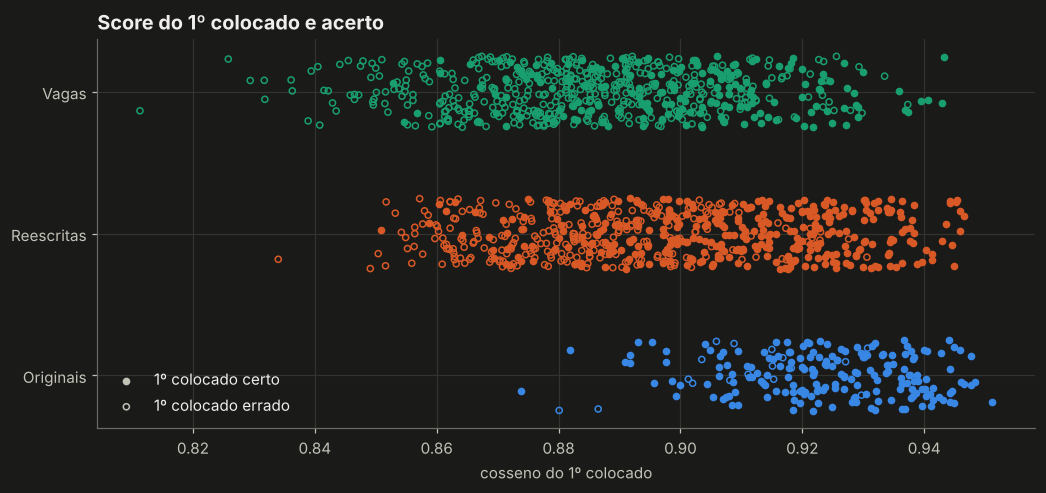

AUROC do score do 1º para separar acerto de erro (reescritas + vagas): 0.800


In [25]:
fig, ax = plt.subplots(figsize=(11, 4.6))
rng = np.random.default_rng(1)
for j, c in enumerate(DENTRO):
    d = validas[validas["conjunto"] == c]
    y = j + rng.uniform(-0.25, 0.25, len(d))
    certo = (d["posicao"] == 1).values
    ax.scatter(d["score_top1"][certo], y[certo], s=16, color=CORES[c])
    ax.scatter(d["score_top1"][~certo], y[~certo], s=16, facecolors="none", edgecolors=CORES[c], linewidths=1)
ax.scatter([], [], s=16, color=TEXTO_2, label="1º colocado certo")
ax.scatter([], [], s=16, facecolors="none", edgecolors=TEXTO_2, label="1º colocado errado")
ax.set_yticks(range(len(DENTRO)), [NOMES[c] for c in DENTRO])
ax.set_xlabel("cosseno do 1º colocado")
ax.set_title("Score do 1º colocado e acerto")
ax.legend(frameon=False, loc="lower left")
plt.show()

print("AUROC do score do 1º para separar acerto de erro (reescritas + vagas):",
      f"{m['separacao'].get('auroc_acerto_top1_entre_validas', float('nan')):.3f}")

Uma AUROC de 0,5 seria acaso, e 1,0, separação perfeita. Um valor perto de 0,8 quer dizer que o
score ajuda, mas não resolve: ainda há muitas respostas erradas com scores tão altos quanto as certas.
Recusar pelo score cortaria muitas respostas certas junto com as erradas.

## 14. Resumo dos achados

Os números abaixo são calculados dos arquivos atuais. O texto em seguida resume a rodada de
15/11/2026 (consultas ainda em rascunho); se a revisão mudar muito os números, ele precisa ser
atualizado.

In [26]:
r = m["ranking"]
print(f"MRR@{K}:    originais {r['original'][f'mrr@{K}']['valor']:.3f} | reescritas {r['reescrita'][f'mrr@{K}']['valor']:.3f} | vagas {r['vaga'][f'mrr@{K}']['valor']:.3f}")
print(f"Recall@{K}: originais {r['original'][f'recall@{K}']['valor']:.3f} | reescritas {r['reescrita'][f'recall@{K}']['valor']:.3f} | vagas {r['vaga'][f'recall@{K}']['valor']:.3f}")
print(f"Livro certo no 1º: reescritas {r['reescrita']['livro_certo@1']['valor']:.3f} | vagas {r['vaga']['livro_certo@1']['valor']:.3f}")
au = m["separacao"]["auroc"]
print(f"AUROC score do 1º (reescrita+vaga): x outro assunto {au['reescrita+vaga x fora_geral']['score_top1']:.3f} | x agro sem livro {au['reescrita+vaga x fora_agro']['score_top1']:.3f}")
print(f"AUROC diferença 1º−2º (reescrita+vaga x fora): {au['reescrita+vaga x fora']['gap_top1_top2']:.3f}")
print(f"Anisotropia: cosseno médio entre chunks {m['anisotropia']['cosseno_medio_entre_chunks']:.3f}, norma do vetor médio {m['anisotropia']['norma_do_vetor_medio']:.3f}")

MRR@10:    originais 0.947 | reescritas 0.620 | vagas 0.375
Recall@10: originais 0.990 | reescritas 0.785 | vagas 0.538
Livro certo no 1º: reescritas 0.798 | vagas 0.642
AUROC score do 1º (reescrita+vaga): x outro assunto 0.965 | x agro sem livro 0.832
AUROC diferença 1º−2º (reescrita+vaga x fora): 0.626
Anisotropia: cosseno médio entre chunks 0.811, norma do vetor médio 0.901


- **O código e o índice estão certos.** As originais acertam o 1º lugar em mais de 90% das vezes;
  a maioria dos erros é uma pergunta igual em outro livro (seção 7).
- **Com outras palavras, a busca cai; com a consulta vaga, cai muito.** Na média das três versões, a
  reescrita põe a resposta no top 10 em cerca de 79% das vezes, e a vaga em cerca de 54% (seção 3).
- **A busca depende das palavras do livro.** Com o termo do livro, quase sempre acha; só com a
  descrição, acha em metade das reescritas e num terço das vagas. O pior caso fica bem
  abaixo da média (seção 4).
- **O erro costuma ser vizinho.** O 1º colocado é do livro certo em 64% a 80% das vezes. Isso
  favorece reordenar perto do topo (reranker, busca híbrida) (seções 3 e 7).
- **Parte das respostas fica longe do top 10** nas vagas, o que nenhum reranker resolve sozinho
  (seção 5).
- **Não há limiar bom para detectar consultas fora do escopo com o score cru.** O score do 1º separa bem outro assunto, mas
  menos agricultura fora dos livros; a diferença 1º−2º ajuda pouco (seções 11 e 12).
- **A anisotropia é forte** (cosseno médio de 0,81 entre chunks sorteados), o que espreme os scores
  e justifica testar a centralização dos vetores (seção 10).
- **O score prevê razoavelmente o acerto** (AUROC perto de 0,80), mas não o bastante para recusar
  com segurança (seção 13).